# GPU kriging and simulation on a large grid

The other demos use a 1 km grid of 22,500 cells, where GStatSim takes a minute or two. Real bed maps are often much larger: finer grids, bigger regions, and many simulated realizations. Run time grows with every cell, so a map that takes minutes at 1 km can take hours at 250 m.

This demo runs the same Greenland data on finer grids with `gstatsim_gpu`, the GPU version of GStatSim's kriging and sequential Gaussian simulation (SGS), and compares the time with GStatSim on the CPU:

* **Kriging** on a 250 m grid (360,000 cells)
* **SGS** on a 500 m grid (90,000 cells), one realization and then 8 at once

A full GStatSim run on these grids takes hours, so its time is measured on a random sample of cells and scaled up. The same sample is used to check that the GPU gives the same values.

You need an NVIDIA GPU and `pip install gstatsim[gpu]`. On an RTX 5060 laptop GPU the whole notebook runs in about 5 minutes.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
from sklearn.preprocessing import QuantileTransformer
import skgstat as skg
import gstatsim as gs
import gstatsim_gpu as gsg

status = gsg.gpu_status()
print("GPU:", status.device_name if status.available else "not available - " + status.reason)

C:\Users\alexi\miniforge3\envs\gstatsim-gpu\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## Load the data

The same radar bed measurements as the other demos.

In [2]:
df_bed = pd.read_csv('data/greenland_test_data.csv')
df_bed = df_bed[df_bed["Bed"] <= 700]   # remove erroneously high values due to bad bed picks
print(f"{len(df_bed):,} measurements")

487,814 measurements


## Grid, transform and fit a variogram

The same steps as the kriging demo, written as a function so we can make grids of different sizes. The normal score transformation and the variogram come from the 500 m grid and are used for both grids.

In [3]:
def grid(res):
    """Gridded data and the prediction grid at resolution res (meters)."""
    df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df_bed, 'X', 'Y', 'Bed', res)
    df_grid = df_grid[df_grid["Z"].isnull() == False].rename(columns={"Z": "Bed"})
    pred_xy = gs.Gridding.prediction_grid(df_grid.X.min(), df_grid.X.max(), df_grid.Y.min(), df_grid.Y.max(), res)
    return df_grid, pred_xy, rows, cols

df_500, pred_500, rows_500, cols_500 = grid(500)
df_250, pred_250, rows_250, cols_250 = grid(250)

# normal score transformation
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(df_500[['Bed']].values)
for df in (df_500, df_250):
    df['Nbed'] = nst_trans.transform(df[['Bed']].values)

# experimental variogram and exponential model
V1 = skg.Variogram(df_500[['X', 'Y']].values, df_500['Nbed'], bin_func='even', n_lags=70,
                   maxlag=50000, normalize=False)
V1.model = 'exponential'
vario = [0, V1.parameters[2], V1.parameters[0], V1.parameters[0], V1.parameters[1], 'Exponential']

k = 100         # number of neighboring data points used to estimate a given point
rad = 50000     # 50 km search radius

for res, df, pred in ((500, df_500, pred_500), (250, df_250, pred_250)):
    print(f"{res} m grid: {len(df):,} cells with data, {len(pred):,} cells to estimate")

500 m grid: 7,816 cells with data, 90,000 cells to estimate
250 m grid: 16,715 cells with data, 360,000 cells to estimate


## Kriging on a 250 m grid

First the GPU kriges every cell. Then GStatSim kriges a random sample of 500 cells, and we scale its time up to the whole grid.

In [4]:
t = time.perf_counter()
est_gpu, var_gpu = gsg.predict(df_250, pred_250, vario, num_points=k, radius=rad, method='ordinary', zz='Nbed')
krige_gpu_s = time.perf_counter() - t
print(f"GPU: {len(pred_250):,} cells in {krige_gpu_s:.0f} s")

sample = np.random.default_rng(0).choice(len(pred_250), 500, replace=False)
t = time.perf_counter()
est_cpu, var_cpu = gs.Interpolation.okrige(pred_250[sample], df_250, 'X', 'Y', 'Nbed', k, vario, rad, quiet=True)
krige_cpu_s = (time.perf_counter() - t) / len(sample) * len(pred_250)
print(f"GStatSim: {len(sample)} cells in {time.perf_counter() - t:.1f} s, "
      f"so about {krige_cpu_s / 60:.0f} min for the whole grid")
print(f"Speedup: about {krige_cpu_s / krige_gpu_s:.0f}x")

GPU: 360,000 cells in 34 s


GStatSim: 500 cells in 4.9 s, so about 58 min for the whole grid
Speedup: about 103x


Do the two agree? On the sampled cells we compare the GPU estimates with GStatSim's. A cell can differ when two data points are exactly the same distance away and only one of them fits in the neighbor search; GStatSim's pick between them depends on the computer it runs on, and the GPU always picks the one that comes first in the data.

In [5]:
diff = np.abs(est_gpu[sample] - est_cpu)
print(f"{np.mean(diff < 1e-6):.0%} of sampled cells agree to 1e-6 (normal score units); "
      f"largest difference {diff.max():.1e}")

91% of sampled cells agree to 1e-6 (normal score units); largest difference 4.1e-02


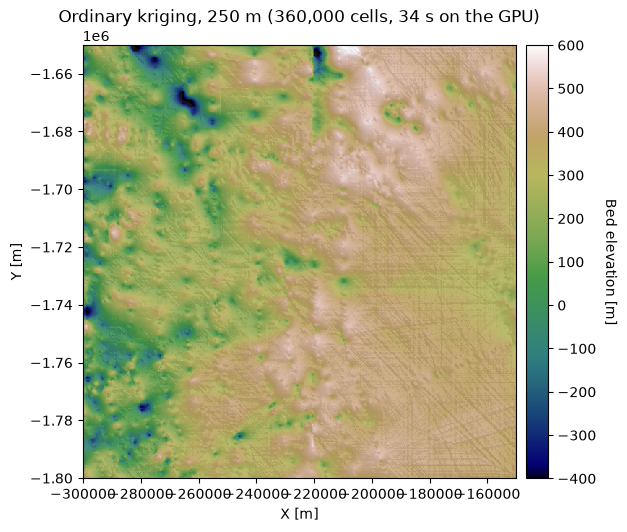

In [6]:
# back transformation and hillshaded map, as in the kriging demo
pred_trans = nst_trans.inverse_transform(est_gpu.reshape(-1, 1))
x_mat = pred_250[:, 0].reshape((rows_250, cols_250))
y_mat = pred_250[:, 1].reshape((rows_250, cols_250))
mat = pred_trans.reshape((rows_250, cols_250))

fig, ax = plt.subplots(1, figsize=(6, 6))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=-400, vmax=600, cmap='gist_earth')
hillshade = LightSource(azdeg=45, altdeg=45).hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
ax.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
ax.set_title(f'Ordinary kriging, 250 m ({len(pred_250):,} cells, {krige_gpu_s:.0f} s on the GPU)')
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.axis('scaled')
cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
plt.show()

## Sequential Gaussian simulation on a 500 m grid

SGS is harder to speed up than kriging. Each cell is conditioned on the data *and* on every cell simulated before it, so the cells of one realization have to be simulated in order. The GPU version keeps that order exactly: it runs a whole realization inside the GPU, and runs different realizations at the same time. One realization is therefore only a little faster than on the CPU, but many realizations take about as long as one.

GStatSim's time is again measured on a sample of 500 cells and scaled up. That underestimates it, because each step gets slower as the simulated cells pile up.

In [7]:
t = time.perf_counter()
sim_one = gsg.sgs(df_500, pred_500, vario, num_points=k, radius=rad, method='ordinary', zz='Nbed', seed=0)
sgs_gpu_one_s = time.perf_counter() - t
print(f"GPU, 1 realization: {sgs_gpu_one_s:.0f} s")

n_real = 8
t = time.perf_counter()
sims = gsg.realizations(df_500, pred_500, vario, seeds=list(range(1, n_real + 1)), num_points=k, radius=rad,
                        method='ordinary', zz='Nbed')
sgs_gpu_many_s = (time.perf_counter() - t) / n_real
print(f"GPU, {n_real} realizations at once: {sgs_gpu_many_s * n_real:.0f} s ({sgs_gpu_many_s:.0f} s each)")

sample = np.random.default_rng(0).choice(len(pred_500), 500, replace=False)
t = time.perf_counter()
gs.Interpolation.okrige_sgs(pred_500[sample], df_500, 'X', 'Y', 'Nbed', k, vario, rad, seed=0, quiet=True)
sgs_cpu_s = (time.perf_counter() - t) / len(sample) * len(pred_500)
print(f"GStatSim: about {sgs_cpu_s / 60:.0f} min per realization (at least)")

GPU, 1 realization: 126 s


GPU, 8 realizations at once: 128 s (16 s each)


GStatSim: about 12 min per realization (at least)


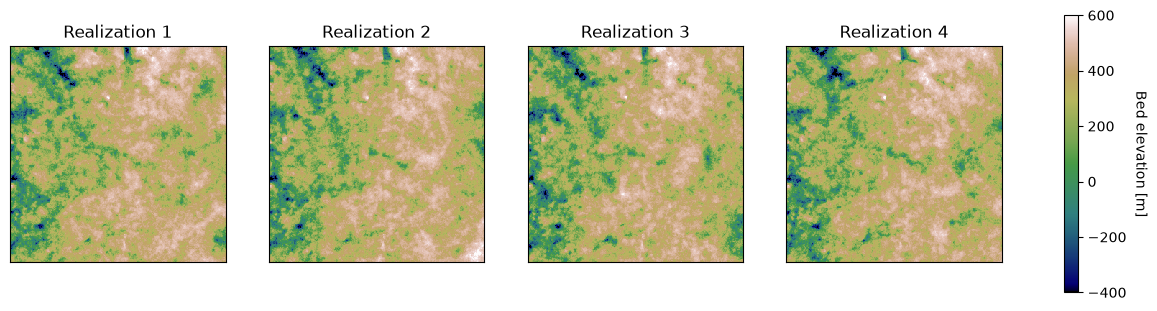

In [8]:
# four of the realizations, back transformed
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
x_mat = pred_500[:, 0].reshape((rows_500, cols_500))
y_mat = pred_500[:, 1].reshape((rows_500, cols_500))
for i, ax in enumerate(axes):
    mat = nst_trans.inverse_transform(sims[i].reshape(-1, 1)).reshape((rows_500, cols_500))
    im = ax.pcolormesh(x_mat, y_mat, mat, vmin=-400, vmax=600, cmap='gist_earth')
    ax.set_title(f'Realization {i + 1}')
    ax.set_xticks([]); ax.set_yticks([])
    ax.axis('scaled')
cbar = fig.colorbar(im, ax=axes, ticks=np.linspace(-400, 600, 6), shrink=0.8)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
plt.show()

## Summary

In [9]:
summary = pd.DataFrame({
    'Task': ['Kriging, 250 m', 'SGS, 500 m, 1 realization', f'SGS, 500 m, {n_real} realizations at once'],
    'Cells': [len(pred_250), len(pred_500), len(pred_500)],
    'GStatSim (CPU, estimated)': [f'{krige_cpu_s / 60:.0f} min', f'{sgs_cpu_s / 60:.0f} min', f'{sgs_cpu_s / 60:.0f} min'],
    'GPU': [f'{krige_gpu_s:.0f} s', f'{sgs_gpu_one_s:.0f} s', f'{sgs_gpu_many_s:.0f} s'],
    'Speedup': [f'{krige_cpu_s / krige_gpu_s:.0f}x', f'{sgs_cpu_s / sgs_gpu_one_s:.0f}x', f'{sgs_cpu_s / sgs_gpu_many_s:.0f}x'],
})
summary

,Task,Cells,"GStatSim (CPU, estimated)",GPU,Speedup
0,"Kriging, 250 m",360000,58 min,34 s,103x
1,"SGS, 500 m, 1 realization",90000,12 min,126 s,6x
2,"SGS, 500 m, 8 realizations at once",90000,12 min,16 s,47x


Times are per realization for SGS. The speedup grows with the size of the grid and with the number of realizations, because the GPU's work is spread over more cells and more realizations at once. For a small grid, or a single realization, GStatSim on the CPU is often fast enough.

Download the tutorial {Download}`here<./11_GPU_large_grid.ipynb>`.